# Build a logistic regression model to classify URLs as either legitimate or malicious. 

In [5]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

In [6]:
df = pd.read_csv("phishing_url_dataset.csv")

print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nLabels:")
print(df["Label"].value_counts())

                                                 URL  Label
0  http://electrocoatingmovilparticulares.mobi/w3...      0
1                       https://www.clonefluence.com      1
2  http://wonoplata.org.ru/olb/5kmxq5zu/mrandapay...      0
3                              https://www.snohd.org      1
4                     https://www.revelrypartyco.com      1

Dataset shape: (200000, 2)

Columns:
Index(['URL', 'Label'], dtype='object')

Labels:
Label
0    100000
1    100000
Name: count, dtype: int64


In [7]:
# Feature extraction functions

def extract_features(url):
    return pd.Series({
        "url_length": len(url),
        "num_dots": url.count("."),
        "num_digits": sum(c.isdigit() for c in url),
        "num_special": len(re.findall(r"[^a-zA-Z0-9]", url)),
        "has_https": int(url.startswith("https://")),
        "has_ip": int(bool(re.search(r"\d{1,3}(\.\d{1,3}){3}", url)))
    })

# Extract features
features = df["URL"].apply(extract_features)

# Add label
features["Label"] = df["Label"]

print(features.head())

print("\nFeature dataset shape:", features.shape)

   url_length  num_dots  num_digits  num_special  has_https  has_ip  Label
0          76         2           7            8          0       0      0
1          28         2           0            5          1       0      1
2          81         2          10           14          0       0      0
3          21         2           0            5          1       0      1
4          30         2           0            5          1       0      1

Feature dataset shape: (200000, 7)


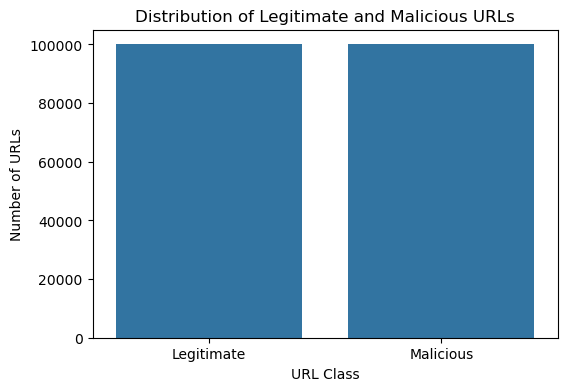

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=features,
    x="Label"
)

plt.title("Distribution of Legitimate and Malicious URLs")
plt.xlabel("URL Class")
plt.ylabel("Number of URLs")

plt.xticks(
    [0, 1],
    ["Legitimate", "Malicious"]
)

plt.show()

In [9]:
# Features
X = features.drop("Label", axis=1)

# Target
y = features["Label"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160000
Testing samples: 40000


In [10]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [11]:
# Predictions
y_pred = model.predict(X_test)

# Probability of malicious class
y_prob = model.predict_proba(X_test)[:, 1]

print("Predictions completed.")
print("First 10 predictions:")
print(y_pred[:10])

Predictions completed.
First 10 predictions:
[1 0 0 0 1 1 0 0 1 1]


In [12]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Malicious"]
    )
)

Accuracy: 0.939225

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.98      0.90      0.94     20000
   Malicious       0.91      0.98      0.94     20000

    accuracy                           0.94     40000
   macro avg       0.94      0.94      0.94     40000
weighted avg       0.94      0.94      0.94     40000



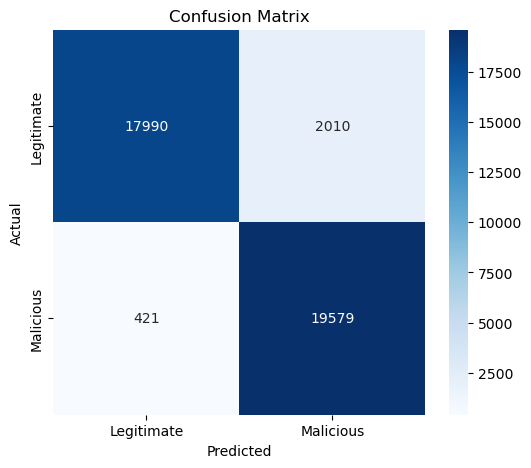

In [13]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Malicious"],
    yticklabels=["Legitimate", "Malicious"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

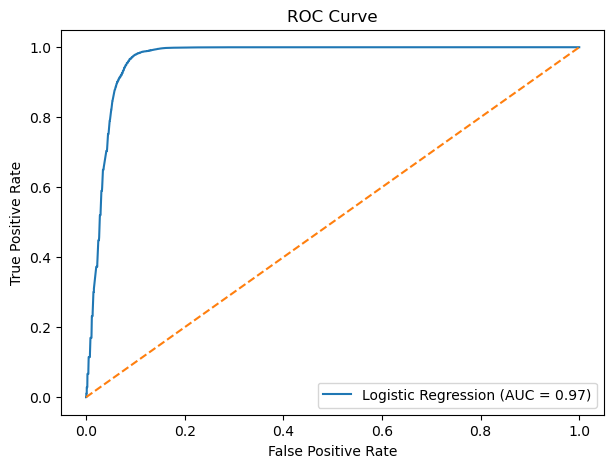

AUC: 0.96750093875


In [14]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.show()

print("AUC:", roc_auc)